# 03 — Analisi statistica del test held-out

Questo notebook quantifica l'incertezza dei risultati del test finale già completato. È un'analisi inferenziale post-hoc: non riesegue le policy, non modifica la selezione congelata e non usa i risultati per scegliere un modello.

Il bootstrap ricampiona gli utenti con reinserimento. Ogni campione mantiene insieme tutte le decisioni temporali dell'utente ed è applicato in modo appaiato alle cinque policy. Gli intervalli descrivono la variabilità tra utenti sotto il protocollo osservato; non catturano automaticamente shock temporali condivisi da utenti diversi.


### Riproducibilità e costo

Gli output salvati sono consultabili senza i file locali. Rieseguire tutte le celle richiede aggregati e checkpoint ufficiali del test e il TSV Last.fm completo; la ricostruzione storica esegue una scansione completa del TSV e usa SQLite temporaneo. Non serve rieseguire il notebook per consultare i risultati incorporati. Vedi `notebooks/README.md`.


## Dati e definizioni

Le metriche di decisione sono macro-medie per utente. Le metriche di ranking e novelty sono ricostruite dai ranking Top-20 nei checkpoint e dalle interazioni Last.fm, seguendo src/evaluation/metrics.py. La rilevanza NDCG usa gli artisti distinti ascoltati dall'utente in (t, t + 7 giorni]; la lista raccomandata prende le prime K track e deduplica gli artisti preservando la prima occorrenza.

Le coverage sono metriche globali di unione tra cataloghi, non medie per utente: vengono riportate come valori ufficiali descrittivi e non ricevono intervalli ottenuti ricampionando utenti.

Il digest canonico del dataset usato dai run è calcolato dal runner sugli eventi identity-resolved in ordine cronologico; non coincide con l'hash byte-per-byte del TSV. Il notebook verifica separatamente il digest canonico riportato nei marker e l'hash fisico del file sorgente.


In [2]:
from __future__ import annotations
import csv, hashlib, io, json, math, mmap, os, sqlite3, tempfile, time
from collections import Counter
from datetime import datetime
from pathlib import Path
from typing import Iterator
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from src.data.identity import resolve_event_identity_keys
from src.experiments.dataset import _parse_timestamp

def repo_root(start):
    for path in (start.resolve(), *start.resolve().parents):
        if (path / "src").is_dir() and (path / "experiments").is_dir():
            return path
    raise FileNotFoundError("Avvia il notebook dalla directory del repository.")

ROOT = repo_root(Path.cwd())
TEST_DIR = ROOT / "experiments/results/test/044f9269d4e3-5b076e7a"
CHECKPOINT_DIR = ROOT / "experiments/results/checkpoints/final-test-044f9269d4e3-5b076e7a1cb3"
CSV_PATH = TEST_DIR / "runs.csv"
AGGREGATE_JSONL = TEST_DIR / "runs.jsonl"
MANIFEST_PATH = ROOT / "experiments/configs/final_selection_manifest.json"
CONFIG_PATH = ROOT / "experiments/configs/final_test.json"
DATASET_PATH = ROOT / "dataset/lastfm-dataset-1K/userid-timestamp-artid-artname-traid-traname.tsv"
TEMP_ROOT = ROOT / ".pytest-tmp"
EXPECTED = {
    "dataset": "5b076e7a1cb3646f58499d53976630528ecd9ac1a2431cb9f8c919a768c7a04a",
    "raw_dataset": "529b8f83aadabdead189de06d816e213557221b92cb43c46f25840e07ef3399a",
    "config": "044f9269d4e3820b8a2ff3e23bd6e191878ccfc421bc6532ac8f5d2ab15b983b",
    "commit": "4cd1fe0dc907ac3620a6f0b08653623fb30608c7",
    "csv": "7089ff59433a1725254da3f5cdd4157fafbe8a11d0140f108cabf18385a27831",
    "aggregate": "c660298186085c6d16f9499c60aa2ab46b4206ea42c14684896c1b724ddc81f8",
    "manifest": "f7d5f9fdbcb36ec4cd15f067aca4632e8895fee4fdfb803e3a4d6d692fdf78b1",
    "final_config": "76e59cefb025579b84f75f4e691387059e76b11b4a08b1c778109c1dabaad40c",
    "scaler": "903fbb2a19d1b6e30608e02943cd5e54e2fa90f87ae514b04f5d19532b8a10b9",
}
RUN_IDS = {
    "random": "e9dd950ba6698a6e", "popularity": "43b15fb56d1fa75d",
    "greedy": "56d64c6681486489", "epsilon_greedy": "27e68f15f1b587f3",
    "linucb": "0178a03a59b83f79",
}
POLICIES = list(RUN_IDS)
LABELS = {
    "random": "Random", "popularity": "Global Popularity", "greedy": "Personalized Greedy",
    "epsilon_greedy": "ε-Greedy (ε=0.05)", "linucb": "LinUCB (α=2.0)",
}
KS = (5, 10, 20)
TOL = 1e-12

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def to_us(value):
    dt = value if isinstance(value, datetime) else _parse_timestamp(value)
    delta = dt - datetime(1970, 1, 1)
    return ((delta.days * 86400 + delta.seconds) * 1_000_000) + delta.microseconds

assert all(p.is_file() for p in [CSV_PATH, AGGREGATE_JSONL, MANIFEST_PATH, CONFIG_PATH, DATASET_PATH])
TEMP_ROOT.mkdir(parents=True, exist_ok=True)
runs = pd.read_csv(CSV_PATH)
manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
hashes = {
    "runs.csv": sha256(CSV_PATH), "runs.jsonl aggregato": sha256(AGGREGATE_JSONL),
    "manifesto": sha256(MANIFEST_PATH), "configurazione finale": sha256(CONFIG_PATH),
}
assert hashes["runs.csv"] == EXPECTED["csv"]
assert hashes["runs.jsonl aggregato"] == EXPECTED["aggregate"]
assert hashes["manifesto"] == EXPECTED["manifest"]
assert hashes["configurazione finale"] == EXPECTED["final_config"]
assert manifest["dataset_content_hash"] == EXPECTED["dataset"]
assert manifest["final_test_config_hash"] == EXPECTED["config"]
assert manifest["selection_status"] == "frozen_before_held_out_test"
assert manifest["selection_rule"]["test_metrics_used_for_selection"] is False
assert manifest["primary_candidate_pool_depth"] == 100
assert config["candidate_pool_depths"] == [100] and config["mode"] == "final_test"
assert set(runs.policy) == set(POLICIES) and len(runs) == 5 and runs.run_id.is_unique
assert set(runs.run_id) == set(RUN_IDS.values())
for row in runs.to_dict("records"):
    assert row["dataset_content_hash"] == EXPECTED["dataset"]
    assert row["configuration_hash"] == EXPECTED["config"]
    assert row["git_commit"] == EXPECTED["commit"]
    assert int(row["candidate_pool_depth"]) == 100
    assert row["scaler_digest"] == EXPECTED["scaler"]
    assert int(row["n_decisions"]) == 82905 and int(row["n_users"]) == 562
    assert row["completion_status"] == "completed"
display(pd.DataFrame([{"Artefatto": key, "SHA-256": value} for key, value in hashes.items()]))

,Artefatto,SHA-256
0,runs.csv,7089ff59433a1725254da3f5cdd4157fafbe8a11d0140f...
1,runs.jsonl aggregato,c660298186085c6d16f9499c60aa2ab46b4206ea42c146...
2,manifesto,f7d5f9fdbcb36ec4cd15f067aca4632e8895fee4fdfb80...
3,configurazione finale,76e59cefb025579b84f75f4e691387059e76b11b4a08b1...


## Struttura e allineamento dei checkpoint

I checkpoint dettagliati sono JSONL a riga singola, di centinaia di megabyte. Il lettore usa memory mapping e decodifica una decisione alla volta. Marker, checksum, identità del run, provenienza, ranking, timestamp e utente vengono verificati prima di stimare l'incertezza.


In [3]:
def iter_decisions(path: Path) -> Iterator[dict]:
    with path.open("rb") as f:
        f.seek(0, os.SEEK_END)
        if f.tell() == 0:
            raise ValueError(f"Checkpoint vuoto: {path}")
        f.seek(0)
        with mmap.mmap(f.fileno(), 0, access=mmap.ACCESS_READ) as data:
            marker = data.find(b'"decisions":[')
            if marker < 0:
                raise ValueError(f"Array decisions assente: {path}")
            pos, end = marker + len(b'"decisions":['), len(data)
            while pos < end:
                while pos < end and data[pos] in b" \t\r\n,":
                    pos += 1
                if pos >= end or data[pos] == ord("]"):
                    return
                start = pos
                if data[pos] != ord("{"):
                    raise ValueError(f"Record non-oggetto al byte {pos}")
                depth, quoted, escape = 0, False, False
                while pos < end:
                    b = data[pos]
                    if quoted:
                        if escape:
                            escape = False
                        elif b == ord("\\"):
                            escape = True
                        elif b == ord('"'):
                            quoted = False
                    elif b == ord('"'):
                        quoted = True
                    elif b == ord("{"):
                        depth += 1
                    elif b == ord("}"):
                        depth -= 1
                        if depth == 0:
                            pos += 1
                            break
                    pos += 1
                if depth or quoted:
                    raise ValueError(f"JSONL incompleto al byte {start}")
                yield json.loads(data[start:pos])
                while pos < end and data[pos] in b" \t\r\n":
                    pos += 1
                if pos < end and data[pos] not in (ord(","), ord("]")):
                    raise ValueError(f"Separatore JSON non valido al byte {pos}")

def intern(mapping, value):
    idx = mapping.get(value)
    if idx is None:
        idx = len(mapping)
        mapping[value] = idx
    return idx

rows = {r["policy"]: r for r in runs.to_dict("records")}
markers, paths = {}, {}
for policy in POLICIES:
    run_id = RUN_IDS[policy]
    marker = json.loads((CHECKPOINT_DIR / f"{run_id}.checkpoint.json").read_text(encoding="utf-8"))
    ident = marker["identity"]
    assert marker["completion_status"] == "completed"
    assert ident["run_id"] == run_id and ident["policy"] == policy
    assert ident["dataset_content_hash"] == EXPECTED["dataset"]
    assert ident["configuration_hash"] == EXPECTED["config"]
    assert ident["git_commit"] == EXPECTED["commit"] and ident["scaler_digest"] == EXPECTED["scaler"]
    detail = CHECKPOINT_DIR / marker["result_filename"]
    assert detail.is_file() and sha256(detail) == marker["result_sha256"]
    assert int(marker["summary"]["n_decisions"]) == 82905
    assert int(marker["summary"]["n_users"]) == 562
    markers[policy], paths[policy] = marker, detail
assert len(list(CHECKPOINT_DIR.glob("*.checkpoint.json"))) == 5
assert len(list(CHECKPOINT_DIR.glob("*.jsonl"))) == 5

base_users, base_times = [], []
for d in iter_decisions(paths["greedy"]):
    base_users.append(d["user_id"])
    base_times.append(to_us(d["decision_time"]))
assert len(base_users) == 82905 and len(set(base_users)) == 562
users = sorted(set(base_users))
user_index = {u: i for i, u in enumerate(users)}
n, p_count = len(base_users), len(POLICIES)
rank_items = np.full((p_count, n, 20), -1, dtype=np.int32)
rank_artists = np.full_like(rank_items, -1)
rewards = np.full((p_count, n), np.nan)
item_ids, artist_ids = {}, {}
times = np.asarray(base_times, dtype=np.int64)
decision_users = np.asarray([user_index[u] for u in base_users], dtype=np.int32)
by_user = [[] for _ in users]
for i, u in enumerate(decision_users):
    by_user[int(u)].append(i)

for pi, policy in enumerate(POLICIES):
    digest = markers[policy]["identity"]["candidate_pool_digest"]
    assert rows[policy]["candidate_pool_digest"] == digest
    assert digest == markers["greedy"]["identity"]["candidate_pool_digest"]
    count = 0
    for i, d in enumerate(iter_decisions(paths[policy])):
        if d["user_id"] != base_users[i] or to_us(d["decision_time"]) != base_times[i]:
            raise AssertionError(f"Decision point non appaiato: {policy}, indice {i}")
        ti, ai = d["top_k_item_keys"], d["top_k_artist_keys"]
        assert len(ti) == len(ai) == int(d["top_k_effective_size"]) <= 20
        if ti:
            assert ti[0] == d["selected_item_key"] and ai[0] == d["selected_artist"]
        for rank, (item, artist) in enumerate(zip(ti, ai)):
            rank_items[pi, i, rank] = intern(item_ids, item)
            rank_artists[pi, i, rank] = intern(artist_ids, artist)
        rewards[pi, i] = np.nan if d["reward"] is None else float(d["reward"])
        count += 1
    assert count == n
assert np.all(np.diff(times) >= 0)
display(pd.DataFrame([{
    "policy": LABELS[q], "decision point": n, "utenti": len(users),
    "timestamp e utenti appaiati": True, "candidate pool digest comune": True,
    "SHA-256 JSONL": markers[q]["result_sha256"],
} for q in POLICIES]))

,policy,decision point,utenti,timestamp e utenti appaiati,candidate pool digest comune,SHA-256 JSONL
0,Random,82905,562,True,True,afaf81ccf23853f79257c3a9c58b05d65f531ffab01bf3...
1,Global Popularity,82905,562,True,True,13e903e2a6e7cceea3b887711d60272ee1527fa8ba58c5...
2,Personalized Greedy,82905,562,True,True,44e243349084e89d68a85a3d0317a7b226d3bad64668c3...
3,ε-Greedy (ε=0.05),82905,562,True,True,aecfeb924e7ad2bcb75222c0645be7c05a4b48b3f47ea8...
4,LinUCB (α=2.0),82905,562,True,True,f076ff08090555d6450118f202db714394cf23a2dca327...


## Ricostruzione fedele delle metriche

Per utente, gli eventi sono ordinati per timestamp. La storia osservabile include esclusivamente eventi con timestamp < t; la rilevanza futura usa (t, t + 7 giorni]. Una finestra mobile aggiorna i conteggi degli artisti futuri in tempo lineare sugli eventi dell'utente.

Si applicano le definizioni del valutatore: Track Novelty conta ogni track; Artist Novelty deduplica gli artisti preservando la prima occorrenza; ILD usa gli artisti delle Top-K track; NDCG usa la rilevanza binaria degli artisti distinti ascoltati nel futuro. Average Reward viene letto dal log e verificato decisione per decisione con log1p del conteggio futuro dell'artista Top-1.


In [4]:
class DigestingRaw(io.RawIOBase):
    def __init__(self, raw, digest):
        self.raw, self.digest = raw, digest
    def readable(self):
        return True
    def readinto(self, buffer):
        size = self.raw.readinto(buffer)
        if size:
            self.digest.update(memoryview(buffer)[:size])
        return size

HORIZON = 7 * 86400 * 1_000_000
METRICS = [f"{name}@{k}" for k in KS for name in ("ndcg", "track_novelty", "artist_novelty", "artist_ild")]
per_user = {pol: {m: np.full(len(users), np.nan) for m in METRICS} for pol in POLICIES}
per_user["average_reward"] = {pol: np.full(len(users), np.nan) for pol in POLICIES}
for pi, pol in enumerate(POLICIES):
    for ui, indices in enumerate(by_user):
        vals = rewards[pi, indices]
        vals = vals[np.isfinite(vals)]
        if len(vals):
            per_user["average_reward"][pol][ui] = vals.mean()

TEMP_ROOT.mkdir(parents=True, exist_ok=True)
temp = tempfile.TemporaryDirectory(prefix="statistical-analysis-", dir=TEMP_ROOT)
db_path = Path(temp.name) / "events.sqlite3"
digest = hashlib.sha256()
physical_rows = indexed_events = 0
start = time.perf_counter()
con = None
reward_max_abs_error = 0.0
try:
    con = sqlite3.connect(db_path)
    con.execute("PRAGMA journal_mode=OFF")
    con.execute("PRAGMA synchronous=OFF")
    con.execute("PRAGMA temp_store=FILE")
    con.execute("PRAGMA cache_size=-65536")
    con.execute("CREATE TABLE events (ordinal INTEGER PRIMARY KEY,user_index INTEGER,timestamp_us INTEGER,item_index INTEGER,artist_index INTEGER)")
    batch = []
    with DATASET_PATH.open("rb") as raw:
        text = io.TextIOWrapper(
            io.BufferedReader(DigestingRaw(raw, digest)),
            encoding="utf-8", errors="replace", newline=""
        )
        reader = csv.reader(text, delimiter="\t", quoting=csv.QUOTE_NONE)
        try:
            for physical_rows, fields in enumerate(reader, 1):
                if len(fields) != 6:
                    raise ValueError(f"TSV riga {physical_rows}: {len(fields)} colonne, attese 6")
                user, stamp, artist_id, artist_name, track_id, track_name = fields
                stamp_us = to_us(_parse_timestamp(stamp))
                ui = user_index.get(user.strip())
                if ui is None:
                    continue
                item_key, artist_key = resolve_event_identity_keys(
                    artist_id or None, artist_name or None, track_id or None, track_name or None
                )
                ai = intern(artist_ids, artist_key)
                ti = item_ids.get(item_key, -1)
                batch.append((physical_rows, ui, stamp_us, ti, ai))
                if len(batch) >= 50000:
                    con.executemany("INSERT INTO events VALUES (?,?,?,?,?)", batch)
                    indexed_events += len(batch)
                    batch.clear()
            if batch:
                con.executemany("INSERT INTO events VALUES (?,?,?,?,?)", batch)
                indexed_events += len(batch)
        finally:
            text.close()
    con.execute("CREATE INDEX events_by_user_time ON events(user_index,timestamp_us,ordinal)")
    con.commit()
    raw_dataset_hash = digest.hexdigest()
    assert raw_dataset_hash == EXPECTED["raw_dataset"]
    assert physical_rows == 19150868
    assert con.execute("SELECT COUNT(*) FROM events").fetchone()[0] == indexed_events

    for ui, indices in enumerate(by_user):
        events = np.asarray(con.execute(
            "SELECT timestamp_us,item_index,artist_index FROM events "
            "WHERE user_index=? ORDER BY timestamp_us,ordinal", (ui,)
        ).fetchall(), dtype=np.int64)
        et, ei, ea = events.T
        seen_items, seen_artists = set(), set()
        observed = left = right = 0
        future = Counter()
        collected = {pol: {m: [] for m in METRICS} for pol in POLICIES}
        for di in indices:
            t = int(times[di])
            while observed < len(et) and et[observed] < t:
                if ei[observed] >= 0:
                    seen_items.add(int(ei[observed]))
                seen_artists.add(int(ea[observed]))
                observed += 1
            while left < len(et) and et[left] <= t:
                if left < right:
                    a = int(ea[left])
                    future[a] -= 1
                    if future[a] == 0:
                        del future[a]
                left += 1
            right = max(right, left)
            while right < len(et) and et[right] <= t + HORIZON:
                future[int(ea[right])] += 1
                right += 1
            for pi, pol in enumerate(POLICIES):
                for k in KS:
                    raw_items = rank_items[pi, di, :k]
                    raw_artists = rank_artists[pi, di, :k]
                    valid = raw_items >= 0
                    items, artists = raw_items[valid], raw_artists[valid]
                    size = len(items)
                    if not size:
                        raise AssertionError("Ranking vuoto per decision point valutabile")
                    collected[pol][f"track_novelty@{k}"].append(
                        sum(int(x) not in seen_items for x in items) / size
                    )
                    ranked, found = [], set()
                    for artist in artists:
                        artist = int(artist)
                        if artist not in found:
                            ranked.append(artist)
                            found.add(artist)
                    collected[pol][f"artist_novelty@{k}"].append(
                        sum(a not in seen_artists for a in ranked) / len(ranked)
                    )
                    if size < 2:
                        ild = 0.0
                    else:
                        counts = Counter(int(a) for a in artists)
                        same = sum(v * (v - 1) for v in counts.values())
                        ild = 1.0 - same / (size * (size - 1))
                    collected[pol][f"artist_ild@{k}"].append(ild)
                    if future and ranked:
                        dcg = sum(1 / math.log2(rank + 2) for rank, a in enumerate(ranked) if future.get(a, 0))
                        ideal = min(k, len(future))
                        idcg = sum(1 / math.log2(rank + 2) for rank in range(ideal))
                        collected[pol][f"ndcg@{k}"].append(min(1.0, dcg / idcg))
                reward = float(rewards[pi, di])
                top_artist = int(rank_artists[pi, di, 0])
                absolute_error = abs(reward - math.log1p(future.get(top_artist, 0)))
                reward_max_abs_error = max(reward_max_abs_error, absolute_error)
        for pol in POLICIES:
            for metric, values in collected[pol].items():
                if values:
                    per_user[pol][metric][ui] = float(np.mean(values))
    assert reward_max_abs_error <= TOL
    scan_seconds = time.perf_counter() - start
finally:
    if con is not None:
        con.close()
    temp.cleanup()
temp_removed = not Path(temp.name).exists()
assert temp_removed
display(pd.DataFrame([
    {"Controllo": "Righe TSV", "Esito": f"{physical_rows:,}"},
    {"Controllo": "Eventi indicizzati dei 562 utenti", "Esito": f"{indexed_events:,}"},
    {"Controllo": "SHA-256 byte del TSV", "Esito": raw_dataset_hash},
    {"Controllo": "Digest canonico dataset nei risultati ufficiali", "Esito": EXPECTED["dataset"]},
    {"Controllo": "Errore massimo reward ricostruito", "Esito": f"{reward_max_abs_error:.3g}"},
    {"Controllo": "SQLite temporaneo rimosso", "Esito": temp_removed},
    {"Controllo": "Secondi scansione e ricostruzione", "Esito": f"{scan_seconds:.1f}"},
]))

,Controllo,Esito
0,Righe TSV,"19,150,868"
1,Eventi indicizzati dei 562 utenti,"15,606,915"
2,SHA-256 byte del TSV,529b8f83aadabdead189de06d816e213557221b92cb43c...
3,Digest canonico dataset nei risultati ufficiali,5b076e7a1cb3646f58499d53976630528ecd9ac1a2431c...
4,Errore massimo reward ricostruito,0
5,SQLite temporaneo rimosso,True
6,Secondi scansione e ricostruzione,980.3


## Equivalenza con i risultati ufficiali

Prima del bootstrap, la ricostruzione viene confrontata con ogni aggregato ufficiale per Average Reward e per NDCG, Track Novelty, Artist Novelty e Artist ILD a K=5, 10, 20. La tolleranza assoluta è 1e-12, con tolleranza relativa zero. Il reward è inoltre verificato decisione per decisione.

Se anche un solo confronto non coincide, il notebook si arresta prima dell'inferenza.


In [5]:
verification_rows = []
for pol in POLICIES:
    for metric in ["average_reward", *METRICS]:
        values = per_user["average_reward"][pol] if metric == "average_reward" else per_user[pol][metric]
        valid = np.isfinite(values)
        reconstructed = float(values[valid].mean()) if valid.any() else np.nan
        official = float(rows[pol][metric])
        error = abs(reconstructed - official)
        verification_rows.append({
            "policy": LABELS[pol], "metrica": metric, "ufficiale": official,
            "ricostruita": reconstructed, "errore assoluto": error,
            "utenti": int(valid.sum()),
            "equivalenza entro 1e-12": bool(np.isclose(reconstructed, official, atol=TOL, rtol=0)),
        })
verification = pd.DataFrame(verification_rows)
display(verification.style.format({
    "ufficiale": "{:.12f}", "ricostruita": "{:.12f}", "errore assoluto": "{:.3g}"
}))
assert verification["equivalenza entro 1e-12"].all()
assert all(np.isfinite(per_user["average_reward"][p]).sum() == 562 for p in POLICIES)

,policy,metrica,ufficiale,ricostruita,errore assoluto,utenti,equivalenza entro 1e-12
0,Random,average_reward,0.083865660021,0.083865660021,4.16e-17,562,True
1,Random,ndcg@5,0.059115226772,0.059115226772,2.78e-17,562,True
2,Random,track_novelty@5,0.881678438107,0.881678438107,1.11e-16,562,True
3,Random,artist_novelty@5,0.462700212847,0.462700212847,5.55e-17,562,True
4,Random,artist_ild@5,0.993376241704,0.993376241704,3.33e-16,562,True
5,Random,ndcg@10,0.058348214220,0.058348214220,9.02e-17,562,True
6,Random,track_novelty@10,0.881661979026,0.881661979026,1.11e-16,562,True
7,Random,artist_novelty@10,0.465039780138,0.465039780138,0,562,True
8,Random,artist_ild@10,0.993400170652,0.993400170652,0,562,True
9,Random,ndcg@20,0.057709377616,0.057709377616,8.33e-17,562,True


## Bootstrap appaiato per utente

10.000 replicazioni, seed 20261022, 562 utenti estratti con reinserimento. La stessa matrice di indici bootstrap è riutilizzata per tutte le policy. Le differenze vengono calcolate tra valori dello stesso utente prima del ricampionamento. Le decisioni temporali di ciascun utente restano aggregate insieme.

Gli intervalli percentile al 95% sono calcolati per Average Reward, NDCG@10, novelty e ILD @10. Le coverage non sono bootstrap per utente perché sono rapporti di unione globale.


In [6]:
B = 10000
SEED = 20261022
BOOT_METRICS = ["average_reward", "ndcg@10", "track_novelty@10", "artist_novelty@10", "artist_ild@10"]
draws = np.random.default_rng(SEED).integers(0, len(users), size=(B, len(users)), dtype=np.int32)

def ci(values):
    values = np.asarray(values, dtype=float)
    point = float(np.nanmean(values))
    sample = values[draws]
    count = np.isfinite(sample).sum(axis=1)
    means = np.divide(np.nansum(sample, axis=1), count, out=np.full(B, np.nan), where=count > 0)
    lo, hi = np.quantile(means[np.isfinite(means)], [0.025, 0.975])
    return point, float(lo), float(hi)

policy_ci_rows = []
for metric in BOOT_METRICS:
    for pol in POLICIES:
        vals = per_user["average_reward"][pol] if metric == "average_reward" else per_user[pol][metric]
        point, lo, hi = ci(vals)
        policy_ci_rows.append({"metrica": metric, "policy": LABELS[pol], "stima": point,
                               "IC95 basso": lo, "IC95 alto": hi, "utenti": int(np.isfinite(vals).sum())})
policy_cis = pd.DataFrame(policy_ci_rows)
display(policy_cis.style.format({"stima": "{:.6f}", "IC95 basso": "{:.6f}", "IC95 alto": "{:.6f}"}))

pairs = [
    ("linucb", "greedy", "LinUCB − Personalized Greedy"),
    ("linucb", "epsilon_greedy", "LinUCB − ε-Greedy"),
    ("epsilon_greedy", "greedy", "ε-Greedy − Personalized Greedy"),
]
diff_rows = []
for metric in BOOT_METRICS:
    for left, right, label in pairs:
        lv = per_user["average_reward"][left] if metric == "average_reward" else per_user[left][metric]
        rv = per_user["average_reward"][right] if metric == "average_reward" else per_user[right][metric]
        delta = lv - rv
        point, lo, hi = ci(delta)
        diff_rows.append({"metrica": metric, "confronto": label, "delta appaiato": point,
                          "IC95 basso": lo, "IC95 alto": hi, "include zero": lo <= 0 <= hi,
                          "utenti appaiati": int(np.isfinite(delta).sum())})
paired_cis = pd.DataFrame(diff_rows)
display(paired_cis.style.format({
    "delta appaiato": "{:+.6f}", "IC95 basso": "{:+.6f}", "IC95 alto": "{:+.6f}"
}))

,metrica,policy,stima,IC95 basso,IC95 alto,utenti
0,average_reward,Random,0.083866,0.075525,0.092418,562
1,average_reward,Global Popularity,0.266868,0.220656,0.314229,562
2,average_reward,Personalized Greedy,0.973338,0.887936,1.064129,562
3,average_reward,ε-Greedy (ε=0.05),0.929997,0.848508,1.016539,562
4,average_reward,LinUCB (α=2.0),0.913353,0.834536,0.997110,562
5,ndcg@10,Random,0.058348,0.053571,0.063261,562
6,ndcg@10,Global Popularity,0.036927,0.031781,0.042009,562
7,ndcg@10,Personalized Greedy,0.258795,0.242648,0.275306,562
8,ndcg@10,ε-Greedy (ε=0.05),0.248893,0.233398,0.264730,562
9,ndcg@10,LinUCB (α=2.0),0.257741,0.241523,0.274255,562


,metrica,confronto,delta appaiato,IC95 basso,IC95 alto,include zero,utenti appaiati
0,average_reward,LinUCB − Personalized Greedy,-0.059984,-0.091307,-0.028959,False,562
1,average_reward,LinUCB − ε-Greedy,-0.016644,-0.046835,+0.013173,True,562
2,average_reward,ε-Greedy − Personalized Greedy,-0.043341,-0.048176,-0.038668,False,562
3,ndcg@10,LinUCB − Personalized Greedy,-0.001055,-0.006601,+0.004389,True,562
4,ndcg@10,LinUCB − ε-Greedy,+0.008848,+0.003464,+0.014129,False,562
5,ndcg@10,ε-Greedy − Personalized Greedy,-0.009902,-0.010780,-0.009050,False,562
6,track_novelty@10,LinUCB − Personalized Greedy,+0.108348,+0.096463,+0.120665,False,562
7,track_novelty@10,LinUCB − ε-Greedy,+0.086488,+0.074930,+0.098442,False,562
8,track_novelty@10,ε-Greedy − Personalized Greedy,+0.021860,+0.020439,+0.023356,False,562
9,artist_novelty@10,LinUCB − Personalized Greedy,+0.101535,+0.086635,+0.117116,False,562


## Grafici e interpretazione

Gli intervalli delle differenze sono centrati sullo zero. Se un intervallo include zero, il bootstrap non determina chiaramente il segno della differenza; ciò non dimostra equivalenza. Gli intervalli sono post-hoc e non corretti per confronti multipli.


LinUCB − Personalized Greedy, average_reward: -0.059984, IC95 [-0.091307, -0.028959] (esclude zero).
LinUCB − ε-Greedy, average_reward: -0.016644, IC95 [-0.046835, +0.013173] (include zero).
LinUCB − Personalized Greedy, ndcg@10: -0.001055, IC95 [-0.006601, +0.004389] (include zero).
LinUCB − ε-Greedy, ndcg@10: +0.008848, IC95 [+0.003464, +0.014129] (esclude zero).


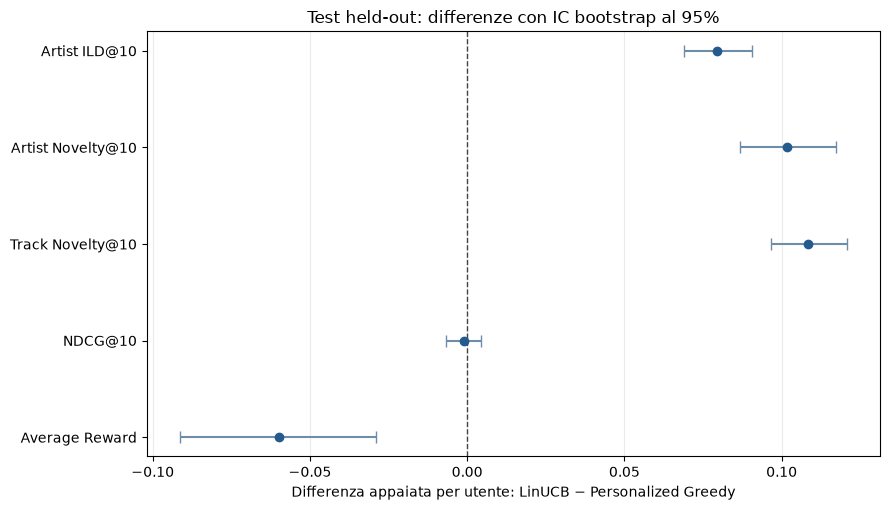

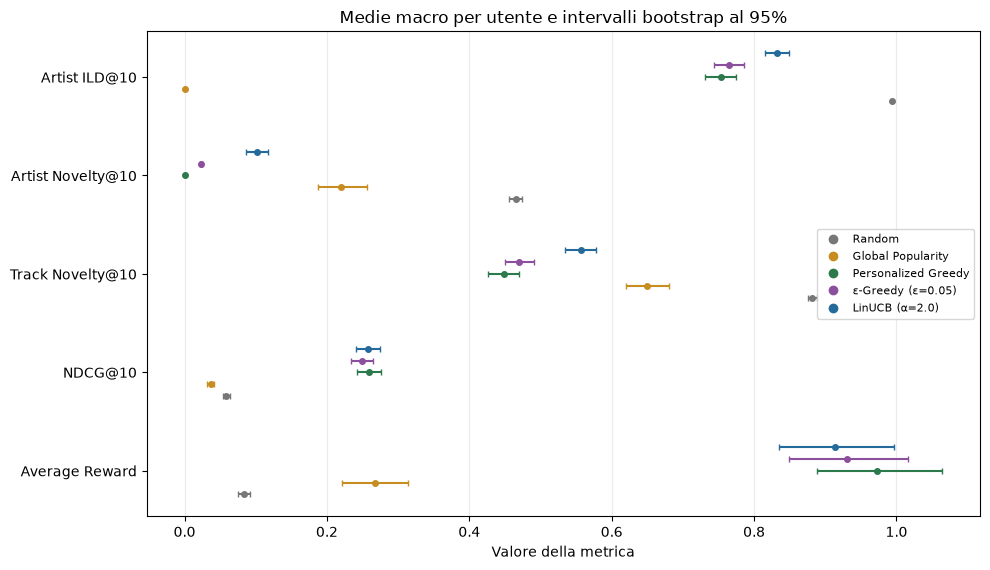

In [7]:
metric_names = {
    "average_reward": "Average Reward", "ndcg@10": "NDCG@10",
    "track_novelty@10": "Track Novelty@10", "artist_novelty@10": "Artist Novelty@10",
    "artist_ild@10": "Artist ILD@10",
}
plot = paired_cis[paired_cis["confronto"] == "LinUCB − Personalized Greedy"].copy()
fig, ax = plt.subplots(figsize=(9, 5.2))
y = np.arange(len(plot))
ax.errorbar(plot["delta appaiato"], y,
            xerr=[plot["delta appaiato"] - plot["IC95 basso"], plot["IC95 alto"] - plot["delta appaiato"]],
            fmt="o", color="#245A8D", ecolor="#6D8DAA", capsize=4)
ax.axvline(0, color="#444", linestyle="--", linewidth=1)
ax.set_yticks(y, [metric_names[m] for m in plot["metrica"]])
ax.set_xlabel("Differenza appaiata per utente: LinUCB − Personalized Greedy")
ax.set_title("Test held-out: differenze con IC bootstrap al 95%")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
display(fig)
plt.close(fig)

colors = ["#777777", "#C78D21", "#2C7A4B", "#8C4F9E", "#246A9B"]
fig, ax = plt.subplots(figsize=(10, 5.8))
for pos, metric in enumerate(BOOT_METRICS):
    part = policy_cis[policy_cis["metrica"] == metric].set_index("policy").loc[[LABELS[policy] for policy in POLICIES]]
    for offset, pol, color in zip(np.linspace(-0.24, 0.24, len(POLICIES)), POLICIES, colors):
        row = part.loc[LABELS[pol]]
        ax.errorbar(row["stima"], pos + offset,
                    xerr=[[row["stima"] - row["IC95 basso"]], [row["IC95 alto"] - row["stima"]]],
                    fmt="o", color=color, capsize=2, markersize=4)
ax.set_yticks(range(len(BOOT_METRICS)), [metric_names[m] for m in BOOT_METRICS])
ax.set_title("Medie macro per utente e intervalli bootstrap al 95%")
ax.set_xlabel("Valore della metrica")
ax.grid(axis="x", alpha=0.25)
ax.legend(handles=[plt.Line2D([0], [0], marker="o", linestyle="", color=c, label=LABELS[p])
                   for p, c in zip(POLICIES, colors)], loc="best", fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

for _, row in paired_cis.iterrows():
    if row["metrica"] in ("average_reward", "ndcg@10") and row["confronto"] in (
        "LinUCB − Personalized Greedy", "LinUCB − ε-Greedy"
    ):
        status = "include zero" if row["include zero"] else "esclude zero"
        print(f'{row["confronto"]}, {row["metrica"]}: {row["delta appaiato"]:+.6f}, '
              f'IC95 [{row["IC95 basso"]:+.6f}, {row["IC95 alto"]:+.6f}] ({status}).')

## Limiti scientifici

Il ricampionamento per utente preserva la dipendenza temporale interna a ciascun utente e appaia le policy sugli stessi utenti e decision point. L'unità ricampionata è l'utente, non la sessione.

L'analisi è post-hoc. Un intervallo che include zero non prova equivalenza; uno che esclude zero non risolve da solo i confronti multipli né dimostra causalità. Gli utenti possono condividere shock temporali (uscite musicali, stagionalità o cambiamenti di piattaforma) che questo bootstrap non ricampiona.

Average Reward è il proxy offline derivato dagli ascolti futuri dell'artista Top-1, non una risposta osservata a una raccomandazione mostrata. Le coverage sono globali e restano valori ufficiali descrittivi, senza intervalli per utente. Nessuna selezione viene effettuata sulla base di questo notebook.


In [8]:
print(f"Bootstrap: {B:,} replicazioni, seed {SEED}, {len(users)} utenti.")
print(f"Tolleranza assoluta per l'equivalenza delle metriche: {TOL:g}, tolleranza relativa 0.")
print("Metriche verificate: Average Reward, NDCG, Track Novelty, Artist Novelty e Artist ILD a K=5, 10, 20.")
print("Coverage globale: valori ufficiali senza bootstrap per utente.")
print("Un intervallo che include zero non dimostra equivalenza statistica.")

Bootstrap: 10,000 replicazioni, seed 20261022, 562 utenti.
Tolleranza assoluta per l'equivalenza delle metriche: 1e-12, tolleranza relativa 0.
Metriche verificate: Average Reward, NDCG, Track Novelty, Artist Novelty e Artist ILD a K=5, 10, 20.
Coverage globale: valori ufficiali senza bootstrap per utente.
Un intervallo che include zero non dimostra equivalenza statistica.
